# Notebook 08M: Development learned peer and view ranker evaluation

**File:** `08m-development-learned-peer-view-ranker.ipynb`

This notebook verifies the locked 08L feature package before opening the development evaluator. It compares the current B0, P1, P2 and forward-patch scores with robust fusion, view voting, winner clustering, a scene-softmax linear ranker, a pairwise RankNet-style ranker and a hybrid objective.

All learned metrics are out-of-fold by source asset. The protected calibration and internal-lock roles are not used.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08M Kaggle Version 2`  
Clean notebook SHA-256: `babadf5cf3f403da571dc02e8f4df3da20fc9a088ad2e1652bbcfa0e7e505c3a`  
Downloaded saved-output SHA-256: `f9f43a4ffcc78c15a31d8fad1ec3d7b72cf90219ab6669567e141b2ef96b6c2f`


## Scientific questions

1. Does any fixed or learned combination improve the automatic three-view result?
2. Is any gain stable across asset-group folds and view schedules?
3. Does the method preserve tie-aware average precision, recall at two and reciprocal rank?
4. Can low-confidence results be routed to review without inventing a universal accuracy gate?
5. Do the predicted boxes, SAM masks and heatmaps support the numerical result?

## Candidate methods

The fixed controls are B0, P1, P2 and the selected forward-patch score. The notebook also tests robust score fusion, view voting and three small linear ranking heads. The pairwise learned head follows the RankNet logistic ranking objective described by Burges and colleagues.

The main new project candidate is **winner consensus**. Each view first votes for its strongest candidate using the forward, P1 and P2 ranks. DINO cosine distance links compatible winners across views. A cluster receives

$$S(c)=\frac{v_c}{V}+\frac{0.5m_c+0.5q_c}{4V},$$

where $v_c$ is the number of supporting views, $V$ is the uploaded view count, $m_c$ is the mean within-view winner margin, and $q_c$ is the mean DINO coherence. The second term is deliberately bounded, so it can break an equal-support tie but cannot overpower one additional view vote. Unsupported singleton winners remain visible and can be routed to review.

Reference: [Learning to Rank using Gradient Descent](https://www.microsoft.com/en-us/research/publication/learning-to-rank-using-gradient-descent/).

In [1]:
from pathlib import Path
from pathlib import PurePosixPath
import hashlib
import json
import os
import shutil
import subprocess
import sys
from zipfile import ZipFile

INPUT_ROOT = Path("/kaggle/input")
WORKING_ROOT = Path("/kaggle/working")
STAGE_NAME = "notebook-08m"
SOURCE_ARCHIVE_NAME = "learned-peer-view-source-v1.zip"
SOURCE_MANIFEST_NAME = "source-manifest.json"

def direct_matches(marker):
    matches = []
    for child in sorted(INPUT_ROOT.iterdir()):
        direct = child / marker
        if direct.exists():
            matches.append(direct.parent if direct.is_file() else direct)
        for nested in sorted(path for path in child.iterdir() if path.is_dir())[:20]:
            candidate = nested / marker
            if candidate.exists():
                matches.append(candidate.parent if candidate.is_file() else candidate)
    unique = sorted({path.resolve() for path in matches})
    if not unique:
        recursive = []
        for candidate in INPUT_ROOT.rglob(marker):
            recursive.append(candidate.parent if candidate.is_file() else candidate)
            if len(recursive) > 8:
                raise RuntimeError(f"Too many recursive matches for {marker}")
        unique = sorted({path.resolve() for path in recursive})
    return unique

def unpack_verified_source():
    manifests = sorted(INPUT_ROOT.rglob(SOURCE_MANIFEST_NAME))
    if len(manifests) != 1:
        raise RuntimeError(f"Expected one {SOURCE_MANIFEST_NAME} input, found {manifests}")
    manifest_path = manifests[0]
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    archive = manifest_path.parent / manifest.get("archive", "")
    if not archive.is_file():
        raise RuntimeError(f"Missing source archive beside {manifest_path}")
    observed_hash = sha256_file(archive)
    if observed_hash != manifest.get("archive_sha256"):
        raise RuntimeError("The source archive hash does not match its manifest")
    extraction_root = Path("/kaggle/temp") / f"vpi-learned-source-{observed_hash[:12]}"
    marker = extraction_root / "learned-peer-view-source/scripts/run_metric_feature_preparation.py"
    if marker.is_file():
        return extraction_root
    temporary = extraction_root.with_name(extraction_root.name + ".partial")
    shutil.rmtree(temporary, ignore_errors=True)
    temporary.mkdir(parents=True)
    with ZipFile(archive) as handle:
        members = handle.infolist()
        if not members or len(members) > 5000:
            raise RuntimeError("The source archive member count is outside the allowed range")
        if sum(member.file_size for member in members) > 100 * 1024 * 1024:
            raise RuntimeError("The source archive exceeds the extraction size limit")
        for member in members:
            relative = PurePosixPath(member.filename)
            if relative.is_absolute() or ".." in relative.parts:
                raise RuntimeError(f"Unsafe source archive member: {member.filename}")
            file_type = (member.external_attr >> 16) & 0o170000
            if file_type == 0o120000:
                raise RuntimeError(f"Source archive contains a symbolic link: {member.filename}")
        handle.extractall(temporary)
    if not (temporary / "learned-peer-view-source/scripts/run_metric_feature_preparation.py").is_file():
        raise RuntimeError("The verified source archive is missing the feature runner")
    shutil.rmtree(extraction_root, ignore_errors=True)
    temporary.replace(extraction_root)
    print(json.dumps({"event": "source_extracted", "archive_sha256": observed_hash}, sort_keys=True))
    return extraction_root

def find_bounded(marker):
    unique = direct_matches(marker)
    if not unique and marker == "scripts/run_metric_feature_preparation.py":
        unpack_verified_source()
        unique = direct_matches(marker)
    if len(unique) != 1:
        raise RuntimeError(f"Expected one {marker} input, found {unique}")
    return unique[0]

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

runtime_versions = {}
for package in ("numpy", "pandas", "scipy", "matplotlib", "pillow"):
    try:
        runtime_versions[package] = __import__("importlib.metadata").metadata.version(package)
    except Exception:
        runtime_versions[package] = "unavailable"

SOURCE_ROOT = find_bounded("scripts/run_metric_feature_preparation.py").parent
SCORING_ROOT = find_bounded("prediction_lock.json")
if not (SCORING_ROOT / "scenes").is_dir():
    raise RuntimeError("The scoring input is missing sealed scene predictions")

sys.path.insert(0, str(SOURCE_ROOT / "src"))
print(json.dumps({
    "event": "preflight_complete",
    "stage": STAGE_NAME,
    "source_root": str(SOURCE_ROOT),
    "scoring_root": str(SCORING_ROOT),
    "scoring_lock_sha256": sha256_file(SCORING_ROOT / "prediction_lock.json"),
    "runtime_versions": runtime_versions,
}, sort_keys=True))
FEATURE_ROOT = find_bounded("shareable/preparation_receipt.json").parent
evaluator_candidates = []
for lock_path in INPUT_ROOT.rglob("artifact_lock.json"):
    candidate = lock_path.parent
    index_path = candidate / "index.json"
    if not index_path.is_file() or not (candidate / "scenes").is_dir():
        continue
    try:
        index = json.loads(index_path.read_text())
    except Exception:
        continue
    expected_keys = {"attributes_source_sha256", "automatic_prediction_sha256", "correspondence_source_sha256", "model_lock_sha256", "role_ledger_sha256"}
    if expected_keys.issubset(index) and len(index.get("scenes", [])) == 100:
        evaluator_candidates.append(candidate.resolve())
if len(set(evaluator_candidates)) != 1:
    raise RuntimeError(f"Expected one evaluator package, found {sorted(set(evaluator_candidates))}")
EVALUATOR_ROOT = sorted(set(evaluator_candidates))[0]
MODEL_INPUT_ROOT = None
model_input_candidates = []
for index_path in INPUT_ROOT.rglob("index.json"):
    candidate = index_path.parent
    if not (candidate / "artifact_lock.json").is_file() or not (candidate / "scenes").is_dir() or not (candidate / "media").is_dir():
        continue
    try:
        index = json.loads(index_path.read_text())
    except Exception:
        continue
    if index.get("study") == "development-scoring-comparison-v1" and index.get("routes") == ["supplied", "automatic"] and len(index.get("scenes", [])) == 100:
        model_input_candidates.append(candidate.resolve())
if len(set(model_input_candidates)) != 1:
    raise RuntimeError(f"Expected one model-input package, found {{sorted(set(model_input_candidates))}}")
MODEL_INPUT_ROOT = sorted(set(model_input_candidates))[0]
print(json.dumps({"event": "evaluation_inputs_located", "feature_root": str(FEATURE_ROOT), "evaluator_root": str(EVALUATOR_ROOT), "model_input_root": str(MODEL_INPUT_ROOT)}, sort_keys=True))

{"event": "preflight_complete", "runtime_versions": {"matplotlib": "3.10.0", "numpy": "2.0.2", "pandas": "2.3.3", "pillow": "11.3.0", "scipy": "1.16.3"}, "scoring_lock_sha256": "12ce9bfc2bb401c29621d91000c53ff4fd39504fc28e55ff8a921e0b5443690d", "scoring_root": "/kaggle/input/notebooks/esreekarreddy/toysad-8k-development-scoring-comparison-full/scoring-comparison-08g", "source_root": "/kaggle/input/datasets/esreekarreddy/vpi-learned-peer-view-source/learned-peer-view-source-v1/learned-peer-view-source", "stage": "notebook-08m"}
{"evaluator_root": "/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-evaluator/evaluator-only", "event": "evaluation_inputs_located", "feature_root": "/kaggle/input/notebooks/esreekarreddy/toysad-8k-development-learned-peer-features/learned-peer-features-08l", "model_input_root": "/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-model-input/model-input"}


## Run grouped out-of-fold evaluation

Feature scaling and model weights are fitted only on the training asset groups in each fold. The automatic route is the deployable result. The supplied-mask route is retained only as a segmentation diagnostic.

In [2]:
OUTPUT_ROOT = WORKING_ROOT / "learned-peer-evaluation-08m"
run_env = os.environ.copy()
run_env["PYTHONPATH"] = str(SOURCE_ROOT / "src")
command = [
    sys.executable,
    str(SOURCE_ROOT / "scripts/run_metric_evaluation.py"),
    "--feature-root", str(FEATURE_ROOT),
    "--scoring-root", str(SCORING_ROOT),
    "--evaluator-root", str(EVALUATOR_ROOT),
    "--model-input-root", str(MODEL_INPUT_ROOT),
    "--output", str(OUTPUT_ROOT),
]
subprocess.run(command, check=True, timeout=3600, env=run_env)

{"artifact_lock_sha256": "cc6d1b64e9ec616087bc2ef787f348e74dd4f9ee5b3f27da302e4fdaa0427221", "asset_groups": 27, "event": "metric_evaluation_complete", "locked_files": 52, "methods": 14, "scenes": 100, "selected_method": "winner_cluster_consensus", "status": "selected_for_frozen_confirmation"}


CompletedProcess(args=['/usr/bin/python3', '/kaggle/input/datasets/esreekarreddy/vpi-learned-peer-view-source/learned-peer-view-source-v1/learned-peer-view-source/scripts/run_metric_evaluation.py', '--feature-root', '/kaggle/input/notebooks/esreekarreddy/toysad-8k-development-learned-peer-features/learned-peer-features-08l', '--scoring-root', '/kaggle/input/notebooks/esreekarreddy/toysad-8k-development-scoring-comparison-full/scoring-comparison-08g', '--evaluator-root', '/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-evaluator/evaluator-only', '--model-input-root', '/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-model-input/model-input', '--output', '/kaggle/working/learned-peer-evaluation-08m'], returncode=0)

## Primary results

The primary table is limited to the automatic route and the fixed three-view schedule. Equal-score candidates are averaged rather than ordered by candidate ID. It reports development evidence, not protected final accuracy.

In [3]:
import pandas as pd
from IPython.display import display, Image as DisplayImage

summary = pd.read_csv(OUTPUT_ROOT / "shareable/method_summary.csv")
primary = summary[(summary.route == "automatic") & (summary.view_set_id == "three-primary")]
columns = [
    "method", "scenes", "asset_groups", "top1_tie_expected",
    "top1_tie_best", "top1_tie_worst", "ap_tie_expected",
    "recall_at_2_tie_expected", "reciprocal_rank_tie_expected",
    "mean_top_tie_count", "mean_margin",
]
display(primary[columns].sort_values(
    ["top1_tie_expected", "reciprocal_rank_tie_expected"],
    ascending=False,
).reset_index(drop=True))
display(json.loads((OUTPUT_ROOT / "shareable/development_decision.json").read_text()))

,method,scenes,asset_groups,top1_tie_expected,top1_tie_best,top1_tie_worst,ap_tie_expected,recall_at_2_tie_expected,reciprocal_rank_tie_expected,mean_top_tie_count,mean_margin
0,winner_cluster_consensus,100,27,0.376667,0.43,0.33,0.476500,0.525833,0.528167,1.17,0.113982
1,winner_cluster_forward,100,27,0.303333,0.53,0.16,0.424306,0.505833,0.480278,1.87,0.133092
2,view_vote_consensus,100,27,0.235000,0.24,0.23,0.339738,0.335000,0.364286,1.05,0.259817
3,view_vote_forward,100,27,0.235000,0.27,0.21,0.333646,0.334167,0.362962,1.18,0.306331
4,soft_support_fusion,100,27,0.220000,0.22,0.22,0.324764,0.300000,0.347242,1.00,0.205734
5,robust_forward,100,27,0.215000,0.26,0.18,0.325076,0.325000,0.350545,1.27,0.240179
6,robust_borda,100,27,0.215000,0.23,0.20,0.313536,0.290000,0.339214,1.07,0.231742
7,P1_current,100,27,0.210000,0.24,0.18,0.311563,0.294167,0.338853,1.21,0.220873
8,forward_02_cov70,100,27,0.205000,0.25,0.17,0.321465,0.334167,0.346851,1.26,0.241845
9,learned_listwise,100,27,0.200000,0.20,0.20,0.309889,0.295000,0.332198,1.00,0.254955


{'baseline': {'ap': 0.3214649470899471,
  'deterministic_top1': 0.24,
  'recall_at_2': 0.33416666666666667,
  'reciprocal_rank': 0.3468505291005291,
  'top1': 0.205},
 'baseline_ap_standard_error': 0.045000986779143326,
 'baseline_recall_at_2_standard_error': 0.047519342995122976,
 'best_grouped_fold_standard_error': 0.02378129326390875,
 'best_observed_method': 'winner_cluster_consensus',
 'candidates': [{'ap': 0.4765,
   'ap_noninferior': True,
   'deterministic_top1': 0.4,
   'folds_improved': 5,
   'method': 'winner_cluster_consensus',
   'recall_at_2': 0.5258333333333334,
   'recall_at_2_noninferior': True,
   'reciprocal_rank': 0.5281666666666667,
   'top1': 0.37666666666666665,
   'top1_difference': 0.17166666666666666,
   'within_one_standard_error': True},
  {'ap': 0.42430555555555555,
   'ap_noninferior': True,
   'deterministic_top1': 0.43,
   'folds_improved': 5,
   'method': 'winner_cluster_forward',
   'recall_at_2': 0.5058333333333334,
   'recall_at_2_noninferior': True,

## Stability and paired evidence

These tables keep the asset-group folds and view-schedule sensitivity visible. A schedule is a repeated measurement of the same scene, not a new sample.

In [4]:
display(pd.read_csv(OUTPUT_ROOT / "shareable/fold_summary.csv").query("route == 'automatic' and view_set_id == 'three-primary'"))
display(pd.read_csv(OUTPUT_ROOT / "shareable/view_schedule_sensitivity.csv").query("route == 'automatic'"))
display(pd.read_csv(OUTPUT_ROOT / "shareable/paired_asset_intervals.csv"))

,route,view_set_id,view_count,method,fold,scenes,top1,top1_tie_expected,ap,ap_tie_expected,recall_at_2,recall_at_2_tie_expected,reciprocal_rank,reciprocal_rank_tie_expected
630,automatic,three-primary,3,B0,0,22,0.227273,0.181818,0.293398,0.265923,0.250000,0.238636,0.335281,0.305709
631,automatic,three-primary,3,B0,1,19,0.157895,0.157895,0.250877,0.254532,0.210526,0.241228,0.257895,0.263743
632,automatic,three-primary,3,B0,2,19,0.210526,0.157895,0.285150,0.265633,0.236842,0.236842,0.309712,0.282519
633,automatic,three-primary,3,B0,3,19,0.052632,0.052632,0.226754,0.223225,0.236842,0.210526,0.240351,0.236508
634,automatic,three-primary,3,B0,4,21,0.476190,0.396825,0.541553,0.505178,0.523810,0.496032,0.590136,0.549792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,automatic,three-primary,3,winner_cluster_forward,0,22,0.363636,0.234848,0.465909,0.388258,0.590909,0.492424,0.522727,0.443182
696,automatic,three-primary,3,winner_cluster_forward,1,19,0.368421,0.280702,0.447368,0.402047,0.552632,0.491228,0.473684,0.418129
697,automatic,three-primary,3,winner_cluster_forward,2,19,0.526316,0.438596,0.539474,0.495614,0.605263,0.539474,0.631579,0.571637
698,automatic,three-primary,3,winner_cluster_forward,3,19,0.473684,0.236842,0.460526,0.361111,0.500000,0.447368,0.570175,0.440058


,route,view_count,method,schedules,scenes,top1,top1_tie_expected,ap,ap_tie_expected,recall_at_2,recall_at_2_tie_expected,reciprocal_rank,reciprocal_rank_tie_expected,schedule_top1_std
0,automatic,1,B0,5,100,0.3820,0.382000,0.600683,0.600683,0.59900,0.599000,0.612667,0.612667,0.059749
1,automatic,1,P1_current,5,100,0.4300,0.429000,0.631533,0.629617,0.64200,0.631000,0.644667,0.642500,0.051889
2,automatic,1,P2_consensus,5,100,0.3920,0.389667,0.607969,0.609867,0.61800,0.627000,0.623267,0.624411,0.058207
3,automatic,1,forward_02_cov70,5,100,0.4820,0.481000,0.659986,0.659652,0.65400,0.654500,0.673333,0.672833,0.050547
4,automatic,1,learned_hybrid,5,100,0.4480,0.452000,0.647302,0.649302,0.66500,0.665000,0.659733,0.661733,0.039623
5,automatic,1,learned_listwise,5,100,0.4460,0.448000,0.646386,0.647386,0.66500,0.665000,0.658733,0.659733,0.040559
6,automatic,1,learned_ranknet,5,100,0.4480,0.450000,0.647736,0.648736,0.66700,0.667000,0.660833,0.661833,0.042131
7,automatic,1,robust_borda,5,100,0.4060,0.406667,0.617486,0.618608,0.62800,0.632833,0.631300,0.632789,0.057819
8,automatic,1,robust_forward,5,100,0.4820,0.481000,0.659986,0.659652,0.65400,0.654500,0.673333,0.672833,0.050547
9,automatic,1,soft_support_fusion,5,100,0.4820,0.484000,0.664319,0.665319,0.66400,0.663500,0.677667,0.678500,0.052010


,method,baseline,measure,difference,ci_low,ci_high,asset_groups,scenes
0,B0,forward_02_cov70,top1_tie_expected,-0.011667,-0.057266,2.921468e-02,27,100
1,B0,forward_02_cov70,ap_tie_expected,-0.015631,-0.047351,1.522837e-02,27,100
2,B0,forward_02_cov70,recall_at_2_tie_expected,-0.046667,-0.109743,1.501562e-02,27,100
3,B0,forward_02_cov70,reciprocal_rank_tie_expected,-0.015412,-0.053762,2.039470e-02,27,100
4,P1_current,forward_02_cov70,top1_tie_expected,0.005000,-0.036667,4.688158e-02,27,100
5,P1_current,forward_02_cov70,ap_tie_expected,-0.009901,-0.036591,1.721544e-02,27,100
6,P1_current,forward_02_cov70,recall_at_2_tie_expected,-0.040000,-0.105180,2.083882e-02,27,100
7,P1_current,forward_02_cov70,reciprocal_rank_tie_expected,-0.007997,-0.039368,2.382138e-02,27,100
8,P2_consensus,forward_02_cov70,top1_tie_expected,-0.010000,-0.040462,1.667088e-02,27,100
9,P2_consensus,forward_02_cov70,ap_tie_expected,-0.014417,-0.037093,7.503188e-03,27,100


## Aggregate figures

Figures cover the primary comparison, view-count behaviour, fold stability, risk-coverage and the strongest hybrid-model coefficients.

fold_stability.png


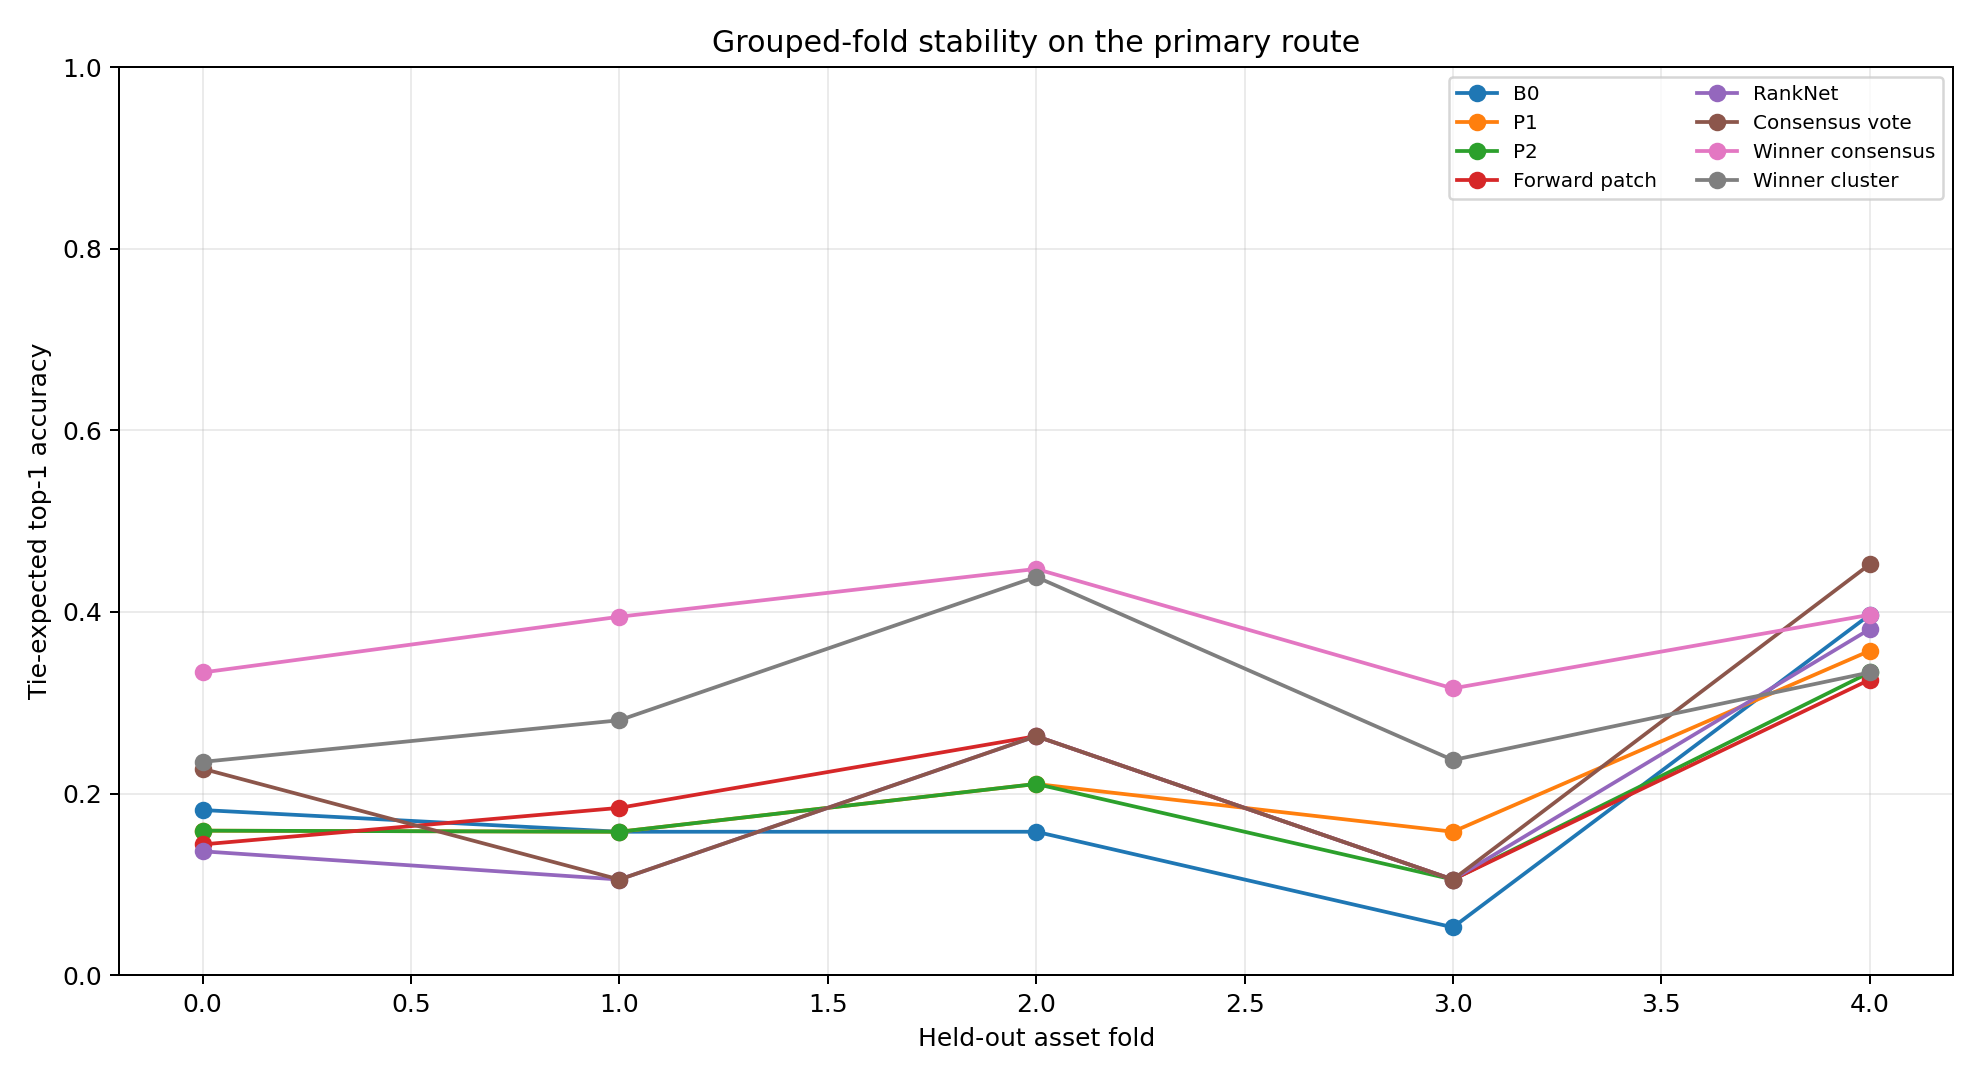

hybrid_coefficients.png


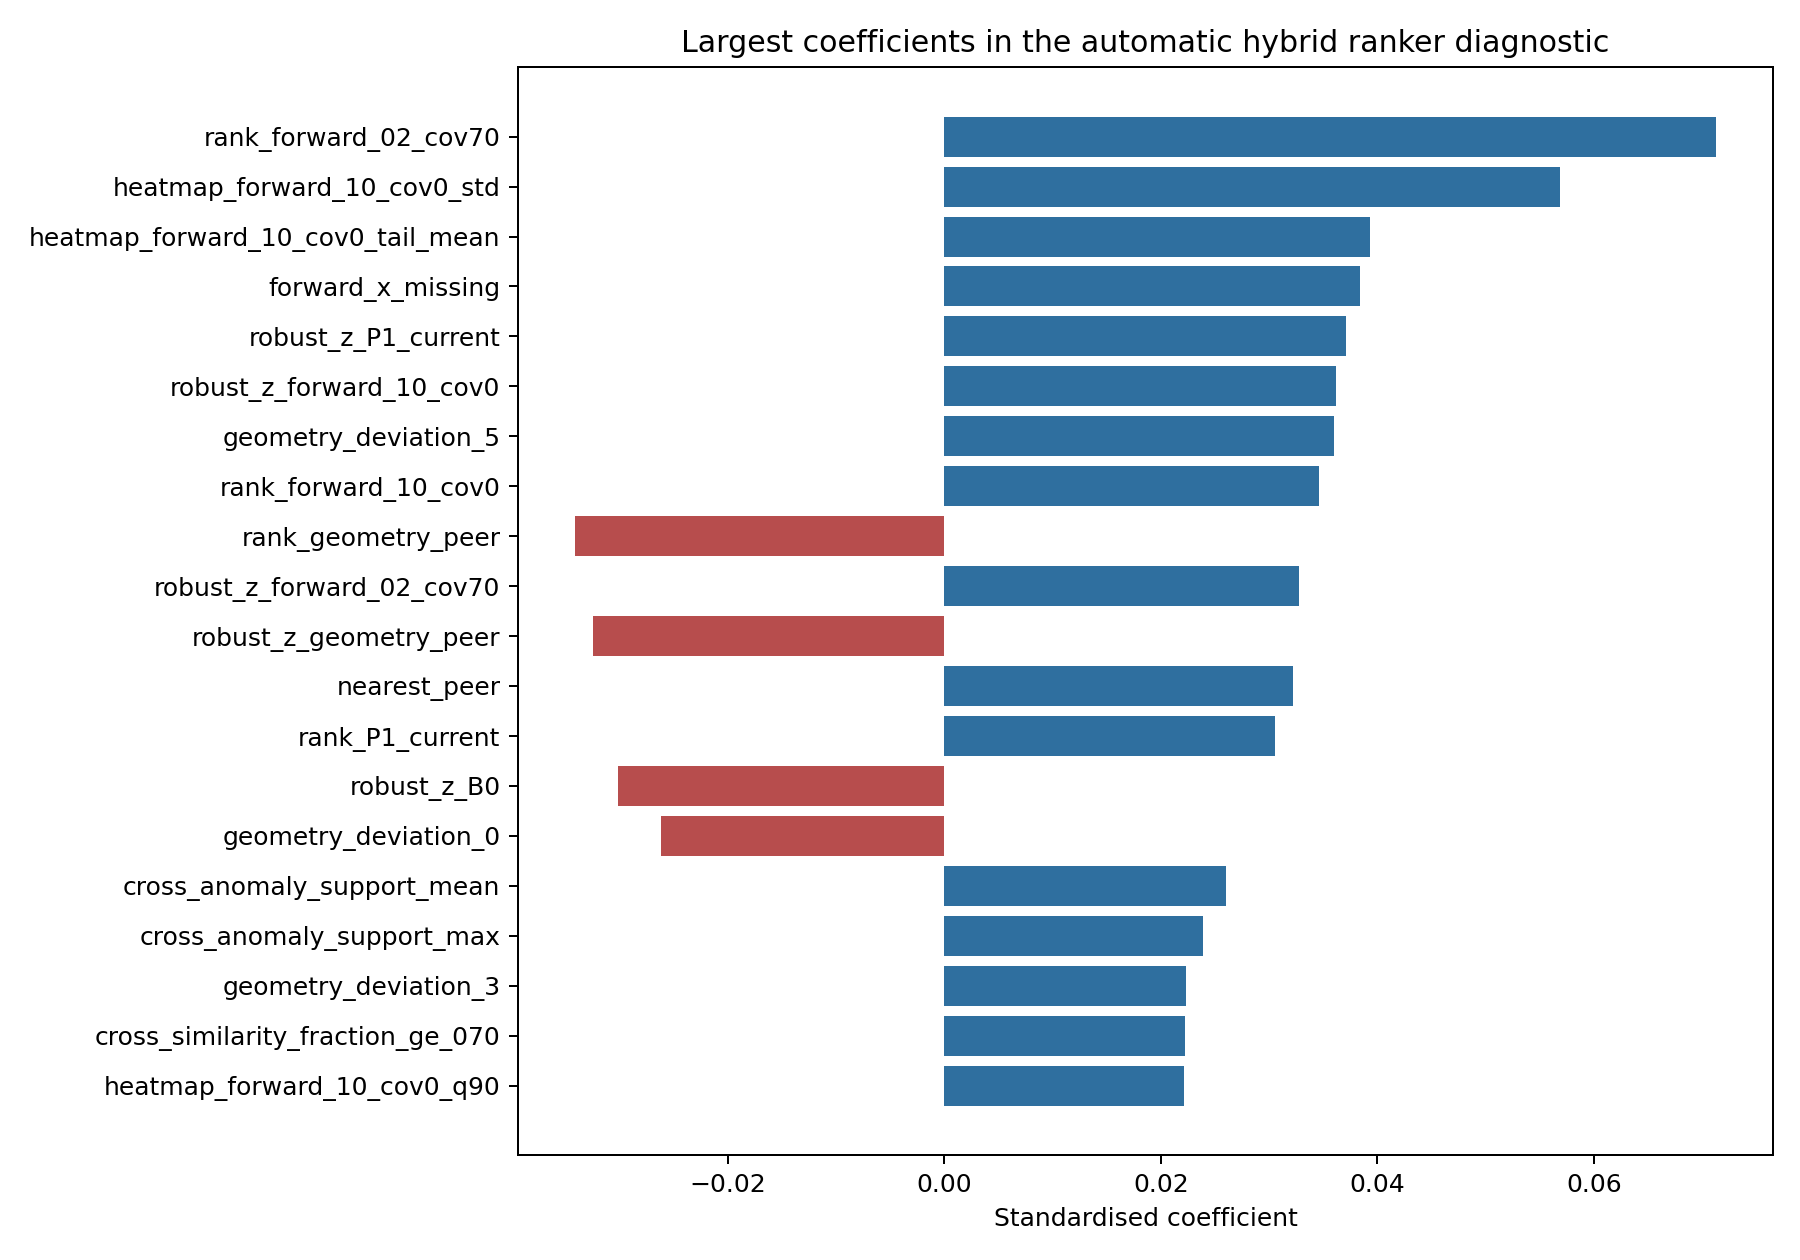

primary_method_comparison.png


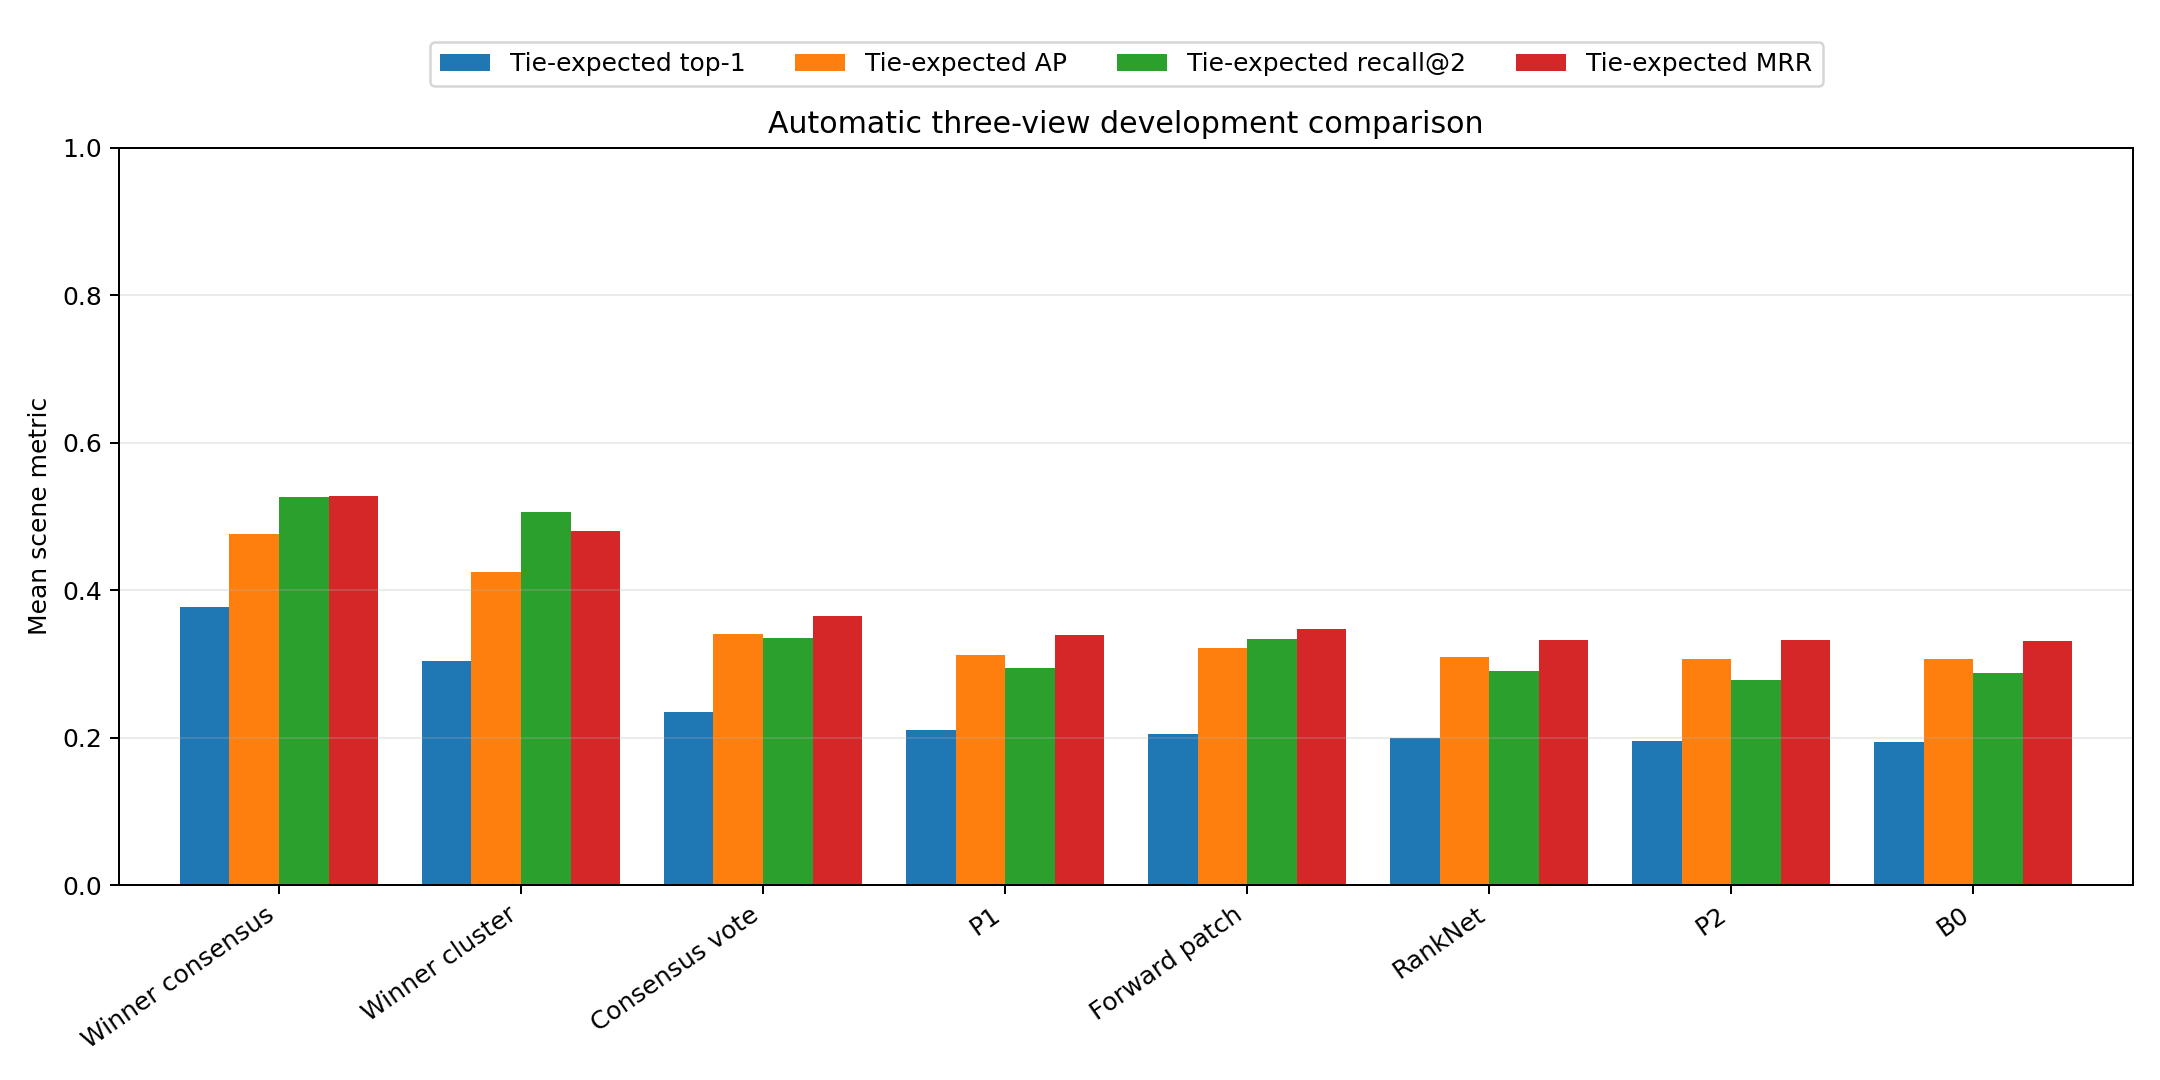

risk_coverage.png


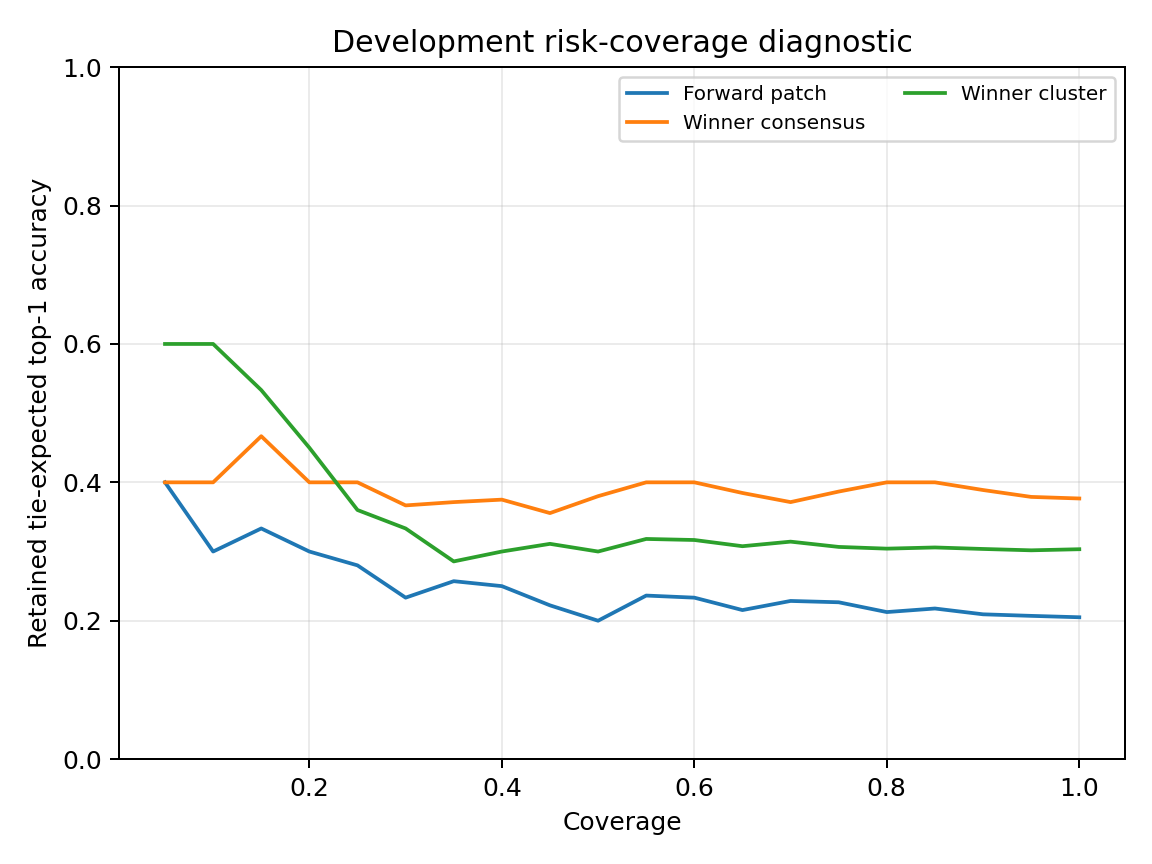

view_count_top1.png


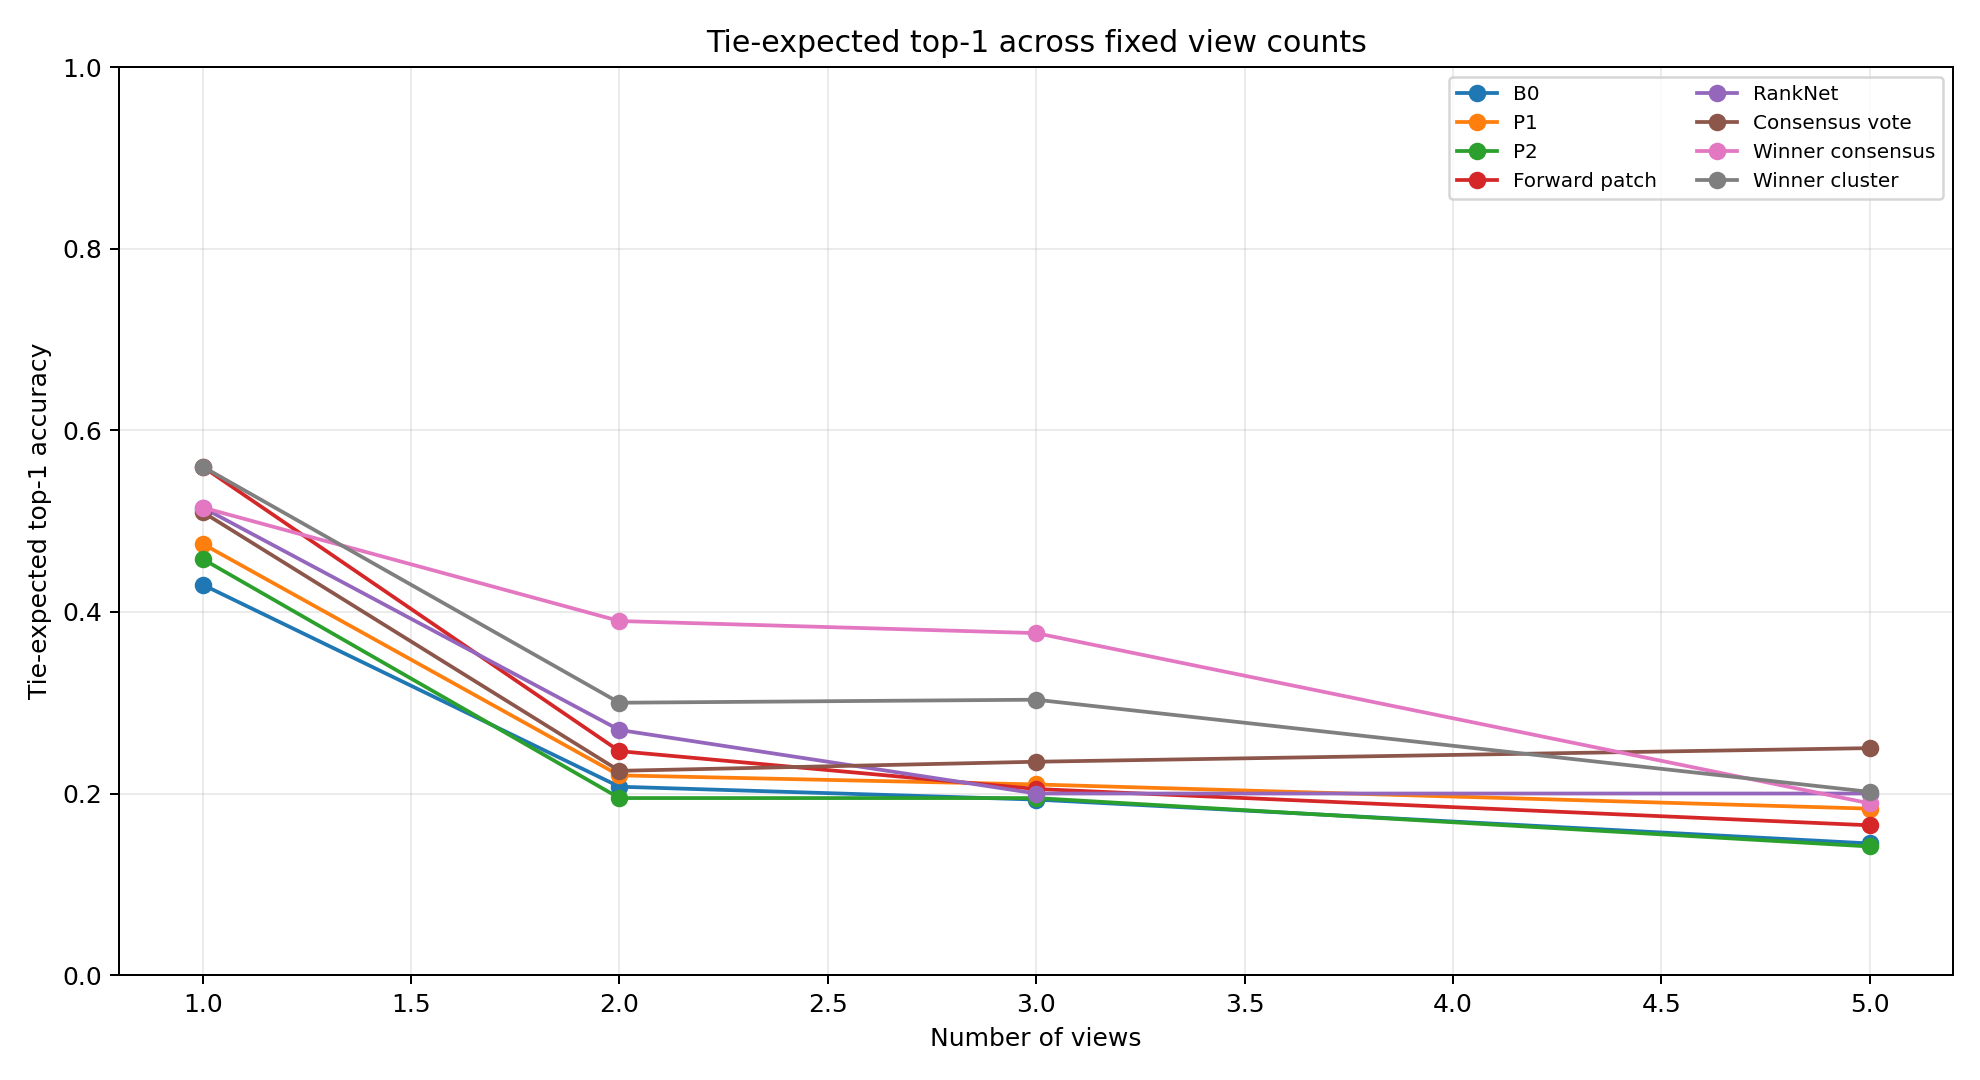

In [5]:
for figure in sorted((OUTPUT_ROOT / "shareable/figures").glob("*.png")):
    print(figure.name)
    display(DisplayImage(filename=str(figure)))

## Qualitative evidence

The private gallery is selected automatically from out-of-fold predictions. Each case shows the selected box, SAM overlay, masked object and forward-patch heatmap for the three uploaded views. It includes correct cases with the strongest cross-view support, uncertain cases and failures from distinct asset groups. Confidence remains an uncalibrated review diagnostic and is not used as an accuracy claim.

In [6]:
gallery = OUTPUT_ROOT / "private/reference_gallery"
display(json.loads((gallery / "gallery_manifest.json").read_text()))
for figure in sorted(gallery.glob("example_*.png")):
    display(DisplayImage(filename=str(figure)))

{'files': ['example_01_supported_correct.png',
  'example_02_supported_correct.png',
  'example_03_supported_correct.png',
  'example_04_supported_correct.png',
  'example_05_uncertain.png',
  'example_06_uncertain.png',
  'example_07_uncertain.png',
  'example_08_uncertain.png',
  'example_09_failure.png',
  'example_10_failure.png',
  'example_11_failure.png',
  'example_12_failure.png'],
 'private': True,
 'selected_method': 'winner_cluster_consensus',
 'selection': 'deterministic out-of-fold definite-correct cases prioritised by cross-view support, ambiguous cases and definite failures, all with distinct asset groups'}

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

...

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

## Package review and repository evidence

Aggregate CSV, JSON and PNG files are separated from private scene-level metrics and image galleries. The later pull request can use the repository-evidence archive after review. The review archive stays outside GitHub.

In [7]:
PACKAGE_ROOT = WORKING_ROOT / "learned-peer-packages-08m"
subprocess.run([
    sys.executable, str(SOURCE_ROOT / "scripts/package_metric_stage.py"),
    "--stage-root", str(OUTPUT_ROOT),
    "--output-root", str(PACKAGE_ROOT),
    "--prefix", "learned-peer-view-08m",
], check=True, timeout=300, env=run_env)
display(json.loads((PACKAGE_ROOT / "learned-peer-view-08m-package-receipt.json").read_text()))

{"event": "metric_stage_packaged", "repository": {"bytes": 1478405, "file": "learned-peer-view-08m-repository-evidence.zip", "members": 17, "sha256": "715d04970261fbe07f457b8b40f4f124ec606425736315e290469f3367e4dea2"}, "review": {"bytes": 29415199, "file": "learned-peer-view-08m-review-evidence.zip", "members": 63, "sha256": "052407bec851f242458319d111339ba520e4d9402aa137d47b93f9529fc07358"}, "schema_version": "metric-stage-package/v1"}


{'repository': {'bytes': 1478405,
  'file': 'learned-peer-view-08m-repository-evidence.zip',
  'members': 17,
  'sha256': '715d04970261fbe07f457b8b40f4f124ec606425736315e290469f3367e4dea2'},
 'review': {'bytes': 29415199,
  'file': 'learned-peer-view-08m-review-evidence.zip',
  'members': 63,
  'sha256': '052407bec851f242458319d111339ba520e4d9402aa137d47b93f9529fc07358'},
 'schema_version': 'metric-stage-package/v1'}

## Optional ClearML record

Only aggregate-safe tables and figures are sent to ClearML. This step runs after the scientific artifact lock and cannot trigger model fitting or change the selection.

In [8]:
# Tracking runs only after the scientific outputs and checksums exist.
tracking_env = os.environ.copy()
tracking_status = "disabled"
try:
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    for key in ("CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY"):
        tracking_env[key] = secrets.get_secret(key)
    tracking_env.setdefault("CLEARML_API_HOST", "https://api.clear.ml")
    tracking_env.setdefault("CLEARML_WEB_HOST", "https://app.clear.ml")
    tracking_env.setdefault("CLEARML_FILES_HOST", "https://files.clear.ml")
    tracking_site = WORKING_ROOT / "clearml-site"
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "--target", str(tracking_site), "clearml==2.1.10"],
        check=True,
        timeout=120,
    )
    tracking_env["PYTHONPATH"] = os.pathsep.join([str(tracking_site), str(SOURCE_ROOT / "src")])
    tracking_env.setdefault("CLEARML_API_DEFAULT_REQ_TIMEOUT", "10")
    subprocess.run(
        [sys.executable, str(SOURCE_ROOT / "scripts/log_learned_metric_clearml.py"),
         "--shareable-root", str(OUTPUT_ROOT / 'shareable'), "--receipt", str(OUTPUT_ROOT / 'tracking_receipt.json'),
         "--task-name", "08M learned peer-view ranker evaluation"],
        check=True,
        timeout=120,
        env=tracking_env,
    )
    tracking_status = json.loads(Path(OUTPUT_ROOT / 'tracking_receipt.json').read_text())["status"]
except Exception as error:
    receipt_path = Path(OUTPUT_ROOT / 'tracking_receipt.json')
    receipt_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_receipt = receipt_path.with_suffix(receipt_path.suffix + ".partial")
    temporary_receipt.write_text(json.dumps({"status": "failed", "error_type": type(error).__name__, "message": str(error)[:500]}, sort_keys=True))
    temporary_receipt.replace(receipt_path)
    tracking_status = "failed"
finally:
    shutil.rmtree(WORKING_ROOT / "clearml-site", ignore_errors=True)
print(json.dumps({"event": "tracking_finished", "status": tracking_status}, sort_keys=True))

{"event": "tracking_finished", "status": "failed"}


## Interpretation boundary

The one-standard-error heuristic keeps the simplest method close to the best grouped-fold result while protecting average precision and recall at two. It is a development selection aid, not a significance test. Winner clustering is also assessed as a selective review aid, but tied winners do not receive deterministic credit. The selected scorer is ready for frozen development confirmation only. Calibration and the internal lock remain later one-shot stages.